In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_curve, f1_score
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


train_df = pd.read_csv('Full_trained.csv', low_memory=False)
test_df = pd.read_csv('Full_test.csv', low_memory=False)

print("Train DataFrame Columns:")
print(train_df.columns.tolist())
print("\nTest DataFrame Columns:")
print(test_df.columns.tolist())

Train DataFrame Columns:
['Flight Type', 'Status', 'Departure IATA Code', 'Departure ICAO Code', 'Departure Terminal', 'Departure Gate', 'Departure Scheduled Time', 'Departure Estimated Time', 'Departure Actual Time', 'Departure Estimated Runway', 'Departure Actual Runway', 'Departure Delay', 'Arrival IATA Code', 'Arrival ICAO Code', 'Arrival Scheduled Time', 'Airline Name', 'Airline ICAO Code', 'Flight Number', 'Flight ICAO Numer', 'Day of Week', 'Hour of Day', 'Month of Year', 'Day of Month', 'Minute of Hour', 'Year', 'Date', 'TIME', 'Max_Temperature', 'Avg_Temperature', 'Min_Temperature', 'Max_Dew_Point', 'Avg_Dew_Point', 'Min_Dew_Point', 'Max_Humidity', 'Avg_Humidity', 'Min_Humidity', 'Max_Wind_Speed', 'Avg_Wind_Speed', 'Min_Wind_Speed', 'Max_Pressure', 'Avg_Pressure', 'Min_Pressure', 'Total_Precipitation']

Test DataFrame Columns:
['Flight Type', 'Status', 'Departure IATA Code', 'Departure ICAO Code', 'Departure Terminal', 'Departure Gate', 'Departure Scheduled Time', 'Departure E

Class Distribution in Training Data:
Delay_Binary
1    0.906189
0    0.093811
Name: proportion, dtype: float64

Total samples: 51572

Model Performance Metrics:
Accuracy: 0.9332
F1 Score: 0.9644
Precision: 0.9375
Recall: 0.9929

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.33      0.47       924
           1       0.94      0.99      0.96      9391

    accuracy                           0.93     10315
   macro avg       0.88      0.66      0.72     10315
weighted avg       0.93      0.93      0.92     10315



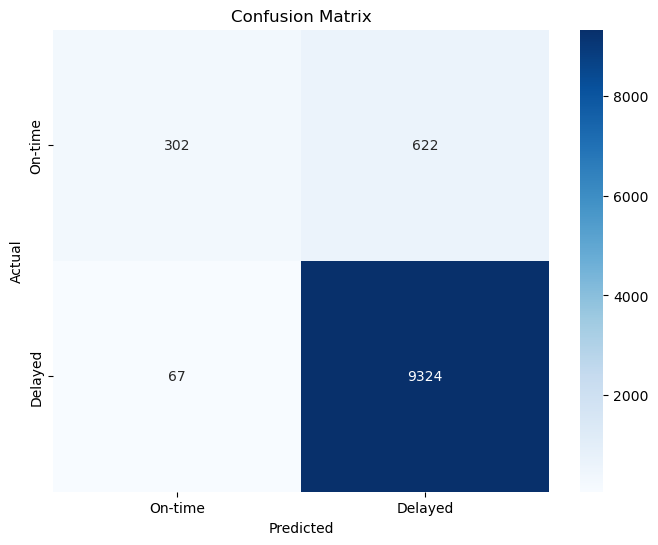

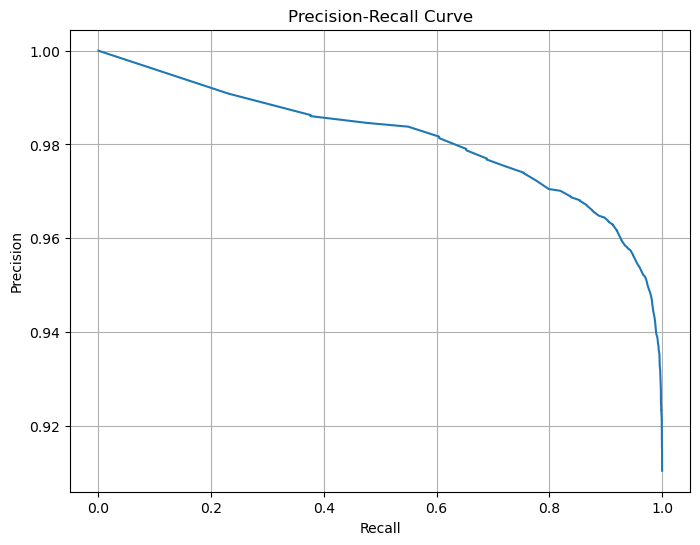

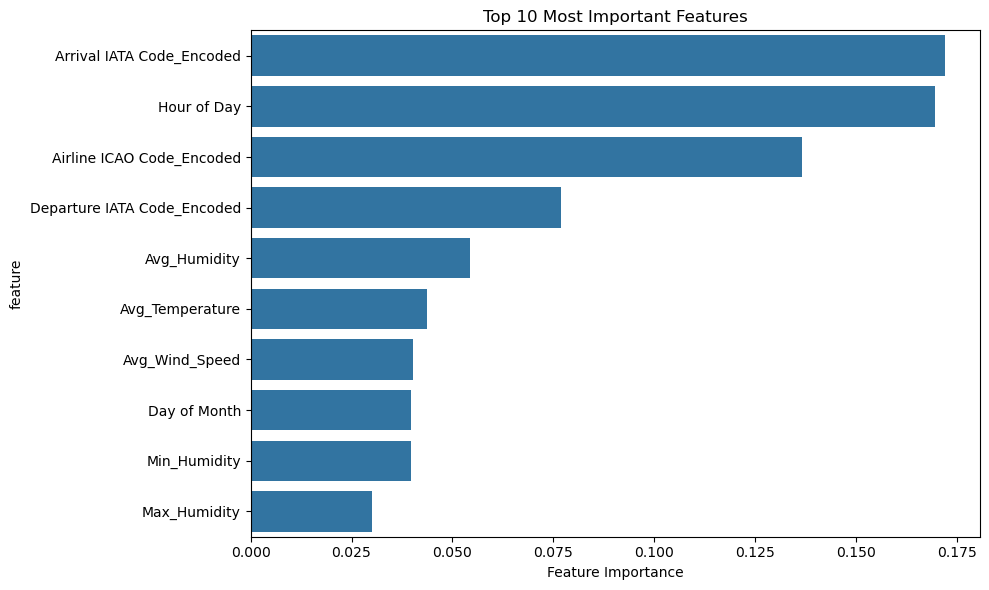


Class-wise Precision-Recall:

On-time flights (Class 0):
Precision: 0.8184
Recall: 0.3268

Delayed flights (Class 1):
Precision: 0.9375
Recall: 0.9929


In [19]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_recall_curve, f1_score, 
    classification_report, confusion_matrix, precision_score, 
    recall_score
)
import seaborn as sns
import matplotlib.pyplot as plt


train_df = pd.read_csv('Full_trained.csv', low_memory=False)
test_df = pd.read_csv('Full_test.csv', low_memory=False)


train_df['Delay_Binary'] = (train_df['Departure Delay'] > 0).astype(int)


print("Class Distribution in Training Data:")
print(train_df['Delay_Binary'].value_counts(normalize=True))
print("\nTotal samples:", len(train_df))


feature_columns = [
    'Hour of Day', 'Month of Year', 'Day of Month',
    'Max_Temperature', 'Avg_Temperature', 'Min_Temperature',
    'Max_Humidity', 'Avg_Humidity', 'Min_Humidity',
    'Max_Wind_Speed', 'Avg_Wind_Speed', 'Min_Wind_Speed',
    'Max_Pressure', 'Avg_Pressure', 'Min_Pressure',
    'Total_Precipitation'
]


categorical_columns = [
    'Flight Type', 'Departure IATA Code', 'Arrival IATA Code',
    'Airline ICAO Code', 'Day of Week'
]


for col in categorical_columns:
    le = LabelEncoder()
    train_df[f'{col}_Encoded'] = le.fit_transform(train_df[col].astype(str))
    feature_columns.append(f'{col}_Encoded')


X = train_df[feature_columns].fillna(0)
y = train_df['Delay_Binary']


from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)

rf_model.fit(X_train_scaled, y_train)


y_pred = rf_model.predict(X_val_scaled)
y_pred_prob = rf_model.predict_proba(X_val_scaled)[:, 1]


accuracy = accuracy_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred)
precision = precision_score(y_val, y_pred)
recall = recall_score(y_val, y_pred)
conf_matrix = confusion_matrix(y_val, y_pred)

print("\nModel Performance Metrics:")
print(f"Accuracy: {accuracy:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_pred))


plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['On-time', 'Delayed'],
            yticklabels=['On-time', 'Delayed'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


precision_curve, recall_curve, _ = precision_recall_curve(y_val, y_pred_prob)
plt.figure(figsize=(8, 6))
plt.plot(recall_curve, precision_curve)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.grid(True)
plt.show()


feature_importance = pd.DataFrame({
    'feature': feature_columns,
    'importance': rf_model.feature_importances_
})
feature_importance = feature_importance.sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feature_importance.head(10))
plt.title('Top 10 Most Important Features')
plt.xlabel('Feature Importance')
plt.tight_layout()
plt.show()


print("\nClass-wise Precision-Recall:")
print("\nOn-time flights (Class 0):")
print(f"Precision: {precision_score(y_val, y_pred, pos_label=0):.4f}")
print(f"Recall: {recall_score(y_val, y_pred, pos_label=0):.4f}")

print("\nDelayed flights (Class 1):")
print(f"Precision: {precision_score(y_val, y_pred, pos_label=1):.4f}")
print(f"Recall: {recall_score(y_val, y_pred, pos_label=1):.4f}")

Initial Class Distribution:
Delay_Binary
1    0.906189
0    0.093811
Name: proportion, dtype: float64

Total samples: 51572

Training model...

Model Performance:

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.43      0.54       968
           1       0.94      0.98      0.96      9347

    accuracy                           0.93     10315
   macro avg       0.83      0.71      0.75     10315
weighted avg       0.92      0.93      0.92     10315



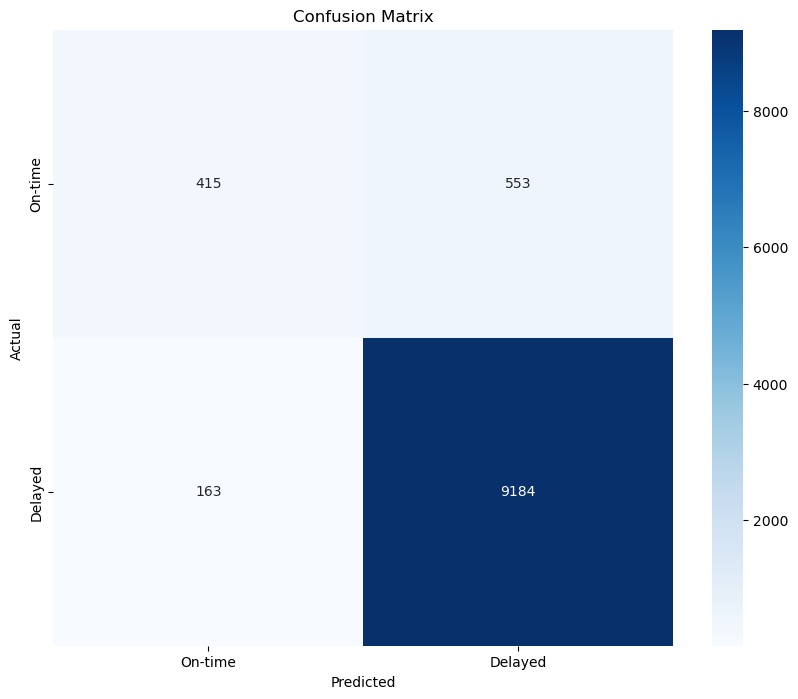

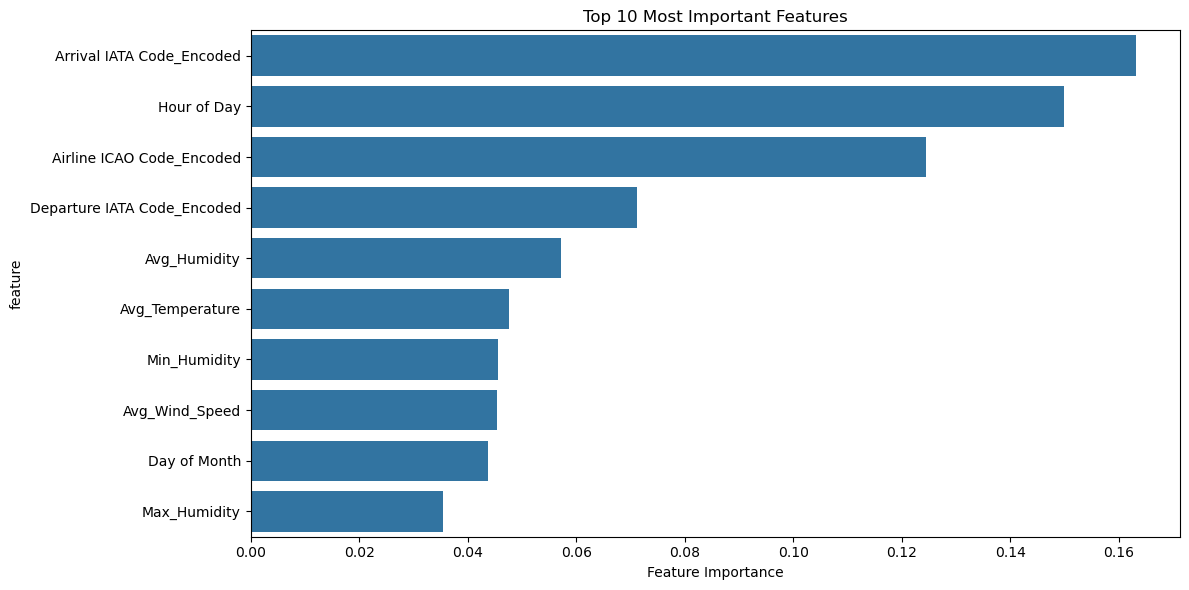


Predictions Distribution:
1    0.943965
0    0.056035
Name: proportion, dtype: float64

Performance at different probability thresholds:

Threshold: 0.3
              precision    recall  f1-score   support

           0       0.86      0.21      0.34       968
           1       0.92      1.00      0.96      9347

    accuracy                           0.92     10315
   macro avg       0.89      0.60      0.65     10315
weighted avg       0.92      0.92      0.90     10315


Threshold: 0.4
              precision    recall  f1-score   support

           0       0.80      0.31      0.45       968
           1       0.93      0.99      0.96      9347

    accuracy                           0.93     10315
   macro avg       0.86      0.65      0.70     10315
weighted avg       0.92      0.93      0.91     10315


Threshold: 0.5
              precision    recall  f1-score   support

           0       0.72      0.43      0.54       968
           1       0.94      0.98      0.96      93

In [25]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


train_df = pd.read_csv('Full_trained.csv', low_memory=False)
train_df['Delay_Binary'] = (train_df['Departure Delay'] > 0).astype(int)

print("Initial Class Distribution:")
print(train_df['Delay_Binary'].value_counts(normalize=True))
print("\nTotal samples:", len(train_df))


feature_columns = [
    'Hour of Day', 'Month of Year', 'Day of Month',
    'Max_Temperature', 'Avg_Temperature', 'Min_Temperature',
    'Max_Humidity', 'Avg_Humidity', 'Min_Humidity',
    'Max_Wind_Speed', 'Avg_Wind_Speed', 'Min_Wind_Speed',
    'Max_Pressure', 'Avg_Pressure', 'Min_Pressure',
    'Total_Precipitation'
]

categorical_columns = [
    'Flight Type', 'Departure IATA Code', 'Arrival IATA Code',
    'Airline ICAO Code', 'Day of Week'
]


for col in categorical_columns:
    train_df[f'{col}_Encoded'] = pd.Categorical(train_df[col]).codes
    feature_columns.append(f'{col}_Encoded')

X = train_df[feature_columns].fillna(0)
y = train_df['Delay_Binary']


from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)


class_weights = {
    0: (y_train == 1).sum() / (y_train == 0).sum(),
    1: 1.0
}


rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,  # Allow full depth
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight=class_weights,
    random_state=42,
    n_jobs=-1
)

print("\nTraining model...")
rf_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred = rf_model.predict(X_val_scaled)
y_pred_proba = rf_model.predict_proba(X_val_scaled)


print("\nModel Performance:")
print("\nClassification Report:")
print(classification_report(y_val, y_pred))


plt.figure(figsize=(10, 8))
conf_matrix = confusion_matrix(y_val, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['On-time', 'Delayed'],
            yticklabels=['On-time', 'Delayed'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


feature_importance = pd.DataFrame({
    'feature': feature_columns,
    'importance': rf_model.feature_importances_
})
feature_importance = feature_importance.sort_values('importance', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x='importance', y='feature', data=feature_importance.head(10))
plt.title('Top 10 Most Important Features')
plt.xlabel('Feature Importance')
plt.tight_layout()
plt.show()


print("\nPredictions Distribution:")
print(pd.Series(y_pred).value_counts(normalize=True))

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]
print("\nPerformance at different probability thresholds:")
for threshold in thresholds:
    y_pred_thresh = (y_pred_proba[:, 1] >= threshold).astype(int)
    print(f"\nThreshold: {threshold}")
    print(classification_report(y_val, y_pred_thresh))


from sklearn.metrics import f1_score
thresholds = np.arange(0.1, 0.9, 0.1)
f1_scores = []
for threshold in thresholds:
    y_pred_t = (y_pred_proba[:, 1] >= threshold).astype(int)
    f1_scores.append(f1_score(y_val, y_pred_t))

optimal_threshold = thresholds[np.argmax(f1_scores)]
print(f"\nOptimal threshold based on F1 score: {optimal_threshold:.2f}")


y_pred_final = (y_pred_proba[:, 1] >= optimal_threshold).astype(int)
print("\nFinal Model Performance (with optimal threshold):")
print(classification_report(y_val, y_pred_final))

Training Data Class Distribution:
Delay_Binary
1    0.906189
0    0.093811
Name: proportion, dtype: float64

Total training samples: 51572

Total test samples: 14910

Training Random Forest model...

Test Set Prediction Distribution:
1    0.938431
0    0.061569
Name: proportion, dtype: float64


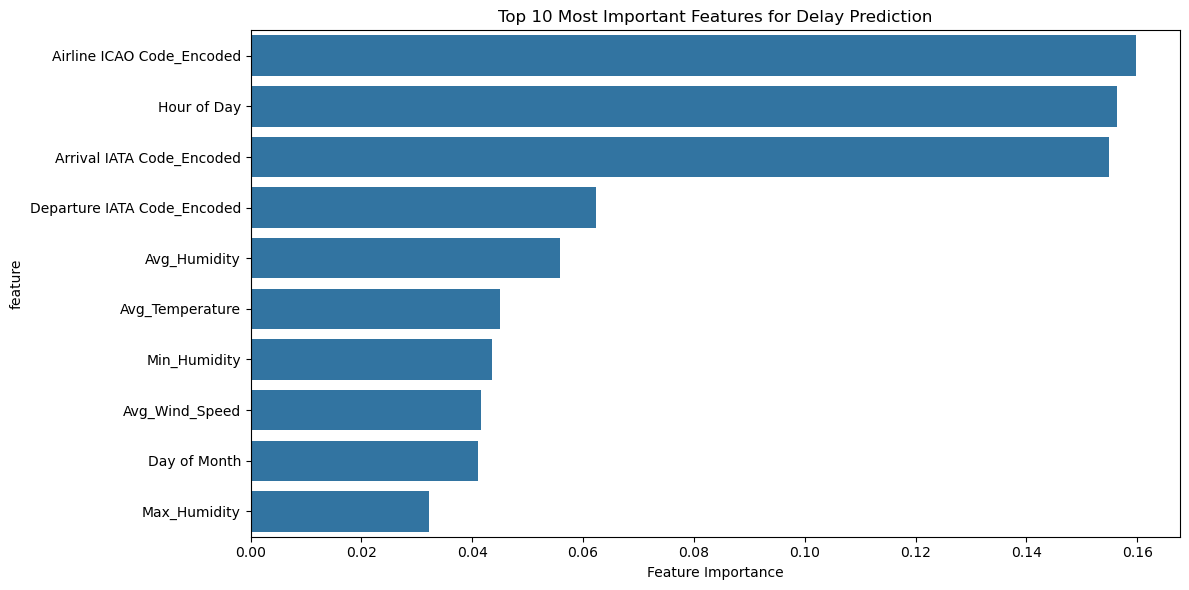


Sample of Flight Delay Predictions:
   Flight_ID Departure IATA Code Arrival IATA Code       Scheduled Time  \
0          0                 lhe               khi  2023-07-17 20:35:00   
1          1                 lhe               ruh  2023-07-27 08:00:00   
2          2                 lhe               dxb  2023-07-27 08:00:00   
3          3                 lhe               jed  2023-07-28 16:45:00   
4          4                 lhe               auh  2023-07-19 04:15:00   
5          5                 lhe               ist  2023-07-15 02:25:00   
6          6                 lhe               ist  2023-07-21 02:25:00   
7          7                 lhe               doh  2023-07-20 21:10:00   
8          8                 lhe               dmm  2023-07-13 20:40:00   
9          9                 lhe               kmg  2023-07-31 22:00:00   

   Predicted_Delay  Delay_Probability  
0                1           0.909970  
1                1           0.938625  
2                

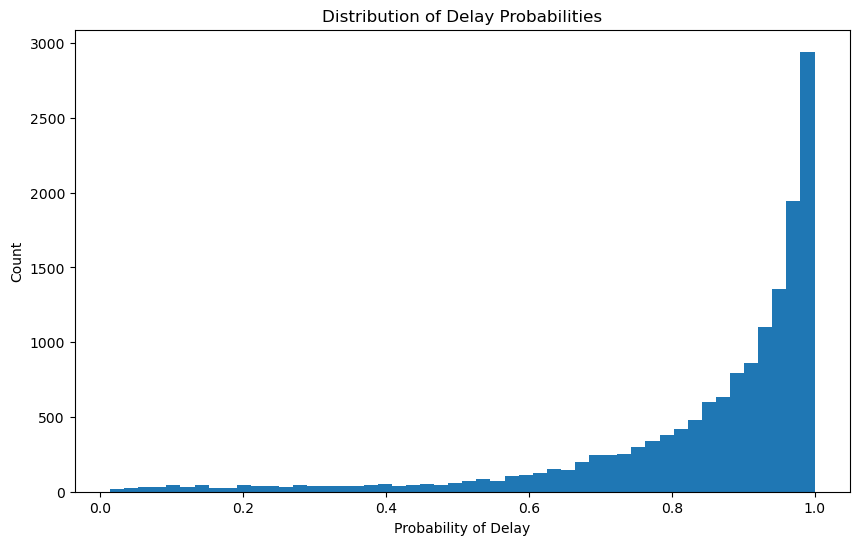

In [29]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
import seaborn as sns
import matplotlib.pyplot as plt


train_df = pd.read_csv('Full_trained.csv', low_memory=False)
test_df = pd.read_csv('Full_test.csv', low_memory=False)


train_df['Delay_Binary'] = (train_df['Departure Delay'] > 0).astype(int)

print("Training Data Class Distribution:")
print(train_df['Delay_Binary'].value_counts(normalize=True))
print("\nTotal training samples:", len(train_df))


feature_columns = [
    'Hour of Day', 'Month of Year', 'Day of Month',
    'Max_Temperature', 'Avg_Temperature', 'Min_Temperature',
    'Max_Humidity', 'Avg_Humidity', 'Min_Humidity',
    'Max_Wind_Speed', 'Avg_Wind_Speed', 'Min_Wind_Speed',
    'Max_Pressure', 'Avg_Pressure', 'Min_Pressure',
    'Total_Precipitation'
]

categorical_columns = [
    'Flight Type', 'Departure IATA Code', 'Arrival IATA Code',
    'Airline ICAO Code', 'Day of Week'
]


for col in categorical_columns:
    # Combine unique values from both datasets
    all_values = pd.concat([train_df[col], test_df[col]]).unique()
    mapping = {val: idx for idx, val in enumerate(all_values)}
    
    # Apply mapping to both datasets
    train_df[f'{col}_Encoded'] = train_df[col].map(mapping)
    test_df[f'{col}_Encoded'] = test_df[col].map(mapping)
    feature_columns.append(f'{col}_Encoded')


X_train = train_df[feature_columns].fillna(0)
y_train = train_df['Delay_Binary']
X_test = test_df[feature_columns].fillna(0)

print(f"\nTotal test samples: {len(X_test)}")


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


print("\nTraining Random Forest model...")
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)


y_pred = rf_model.predict(X_test_scaled)
y_pred_proba = rf_model.predict_proba(X_test_scaled)


print("\nTest Set Prediction Distribution:")
print(pd.Series(y_pred).value_counts(normalize=True))


feature_importance = pd.DataFrame({
    'feature': feature_columns,
    'importance': rf_model.feature_importances_
})
feature_importance = feature_importance.sort_values('importance', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x='importance', y='feature', data=feature_importance.head(10))
plt.title('Top 10 Most Important Features for Delay Prediction')
plt.xlabel('Feature Importance')
plt.tight_layout()
plt.show()


predictions_df = pd.DataFrame({
    'Flight_ID': test_df.index,
    'Departure IATA Code': test_df['Departure IATA Code'],
    'Arrival IATA Code': test_df['Arrival IATA Code'],
    'Scheduled Time': test_df['Departure Scheduled Time'],
    'Predicted_Delay': y_pred,
    'Delay_Probability': y_pred_proba[:, 1]
})


print("\nSample of Flight Delay Predictions:")
print(predictions_df.head(10))


predictions_df.to_csv('flight_delay_predictions.csv', index=False)

print("\nPrediction Probability Distribution:")
plt.figure(figsize=(10, 6))
plt.hist(y_pred_proba[:, 1], bins=50)
plt.title('Distribution of Delay Probabilities')
plt.xlabel('Probability of Delay')
plt.ylabel('Count')
plt.show()

In [31]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier


train_df = pd.read_csv('Full_trained.csv', low_memory=False)
test_df = pd.read_csv('Full_test.csv', low_memory=False)


train_df['Delay_Binary'] = (train_df['Departure Delay'] > 0).astype(int)

print("Training Data Class Distribution:")
print(train_df['Delay_Binary'].value_counts(normalize=True))
print("\nTotal training samples:", len(train_df))


feature_columns = [
    'Hour of Day', 'Month of Year', 'Day of Month',
    'Max_Temperature', 'Avg_Temperature', 'Min_Temperature',
    'Max_Humidity', 'Avg_Humidity', 'Min_Humidity',
    'Max_Wind_Speed', 'Avg_Wind_Speed', 'Min_Wind_Speed',
    'Max_Pressure', 'Avg_Pressure', 'Min_Pressure',
    'Total_Precipitation'
]

categorical_columns = [
    'Flight Type', 'Departure IATA Code', 'Arrival IATA Code',
    'Airline ICAO Code', 'Day of Week'
]


for col in categorical_columns:
    
    all_values = pd.concat([train_df[col], test_df[col]]).unique()
    mapping = {val: idx for idx, val in enumerate(all_values)}
    
    
    train_df[f'{col}_Encoded'] = train_df[col].map(mapping)
    test_df[f'{col}_Encoded'] = test_df[col].map(mapping)
    feature_columns.append(f'{col}_Encoded')


X_train = train_df[feature_columns].fillna(0)
y_train = train_df['Delay_Binary']
X_test = test_df[feature_columns].fillna(0)

print(f"\nTotal test samples: {len(X_test)}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


print("\nTraining Random Forest model...")
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)


y_pred = rf_model.predict(X_test_scaled)


submission_df = pd.DataFrame({
    'ID': range(1, len(y_pred) + 1),  
    'Delay': y_pred  
})

print("\nSubmission File Preview:")
print(submission_df.head(10))

print("\nSubmission File Statistics:")
print(submission_df['Delay'].value_counts(normalize=True))
print("\nTotal predictions:", len(submission_df))


print("\nSubmission File Columns:", submission_df.columns.tolist())
print("ID range:", submission_df['ID'].min(), "to", submission_df['ID'].max())
print("Unique values in Delay column:", submission_df['Delay'].unique())


submission_df.to_csv('binaryclass.csv', index=False)

print("\nSubmission file 'binaryclass.csv' has been created with the following specifications:")
print("- Column names: ID, Delay")
print("- ID: Sequential numbers from 1 to", len(y_pred))
print("- Delay: Binary values (0: on-time, 1: delayed)")
print("- Total rows:", len(submission_df))


print("\nVerifying submission file integrity...")
verification_df = pd.read_csv('binaryclass.csv')
print("\nVerification Results:")
print("1. File can be read back successfully:", len(verification_df) == len(y_pred))
print("2. Columns are correct:", verification_df.columns.tolist() == ['ID', 'Delay'])
print("3. ID starts at 1:", verification_df['ID'].min() == 1)
print("4. ID is sequential:", all(verification_df['ID'] == range(1, len(y_pred) + 1)))
print("5. Delay values are binary:", set(verification_df['Delay'].unique()) <= {0, 1})

Training Data Class Distribution:
Delay_Binary
1    0.906189
0    0.093811
Name: proportion, dtype: float64

Total training samples: 51572

Total test samples: 14910

Training Random Forest model...

Submission File Preview:
   ID  Delay
0   1      1
1   2      1
2   3      1
3   4      1
4   5      1
5   6      1
6   7      1
7   8      1
8   9      1
9  10      1

Submission File Statistics:
Delay
1    0.938431
0    0.061569
Name: proportion, dtype: float64

Total predictions: 14910

Submission File Columns: ['ID', 'Delay']
ID range: 1 to 14910
Unique values in Delay column: [1 0]

Submission file 'binaryclass.csv' has been created with the following specifications:
- Column names: ID, Delay
- ID: Sequential numbers from 1 to 14910
- Delay: Binary values (0: on-time, 1: delayed)
- Total rows: 14910

Verifying submission file integrity...

Verification Results:
1. File can be read back successfully: True
2. Columns are correct: True
3. ID starts at 1: True
4. ID is sequential: True
5.

Delay Category Distribution in Training Data:
Delay_Category
Short Delay       0.814240
No Delay          0.093811
Moderate Delay    0.068099
Long Delay        0.023850
Name: proportion, dtype: float64

Total samples: 51572

Training multi-class Random Forest model...

Classification Report:
                precision    recall  f1-score   support

    Long Delay       0.20      0.09      0.12       246
Moderate Delay       0.31      0.18      0.23       702
      No Delay       0.66      0.43      0.52       968
   Short Delay       0.86      0.94      0.90      8399

      accuracy                           0.82     10315
     macro avg       0.51      0.41      0.44     10315
  weighted avg       0.79      0.82      0.80     10315



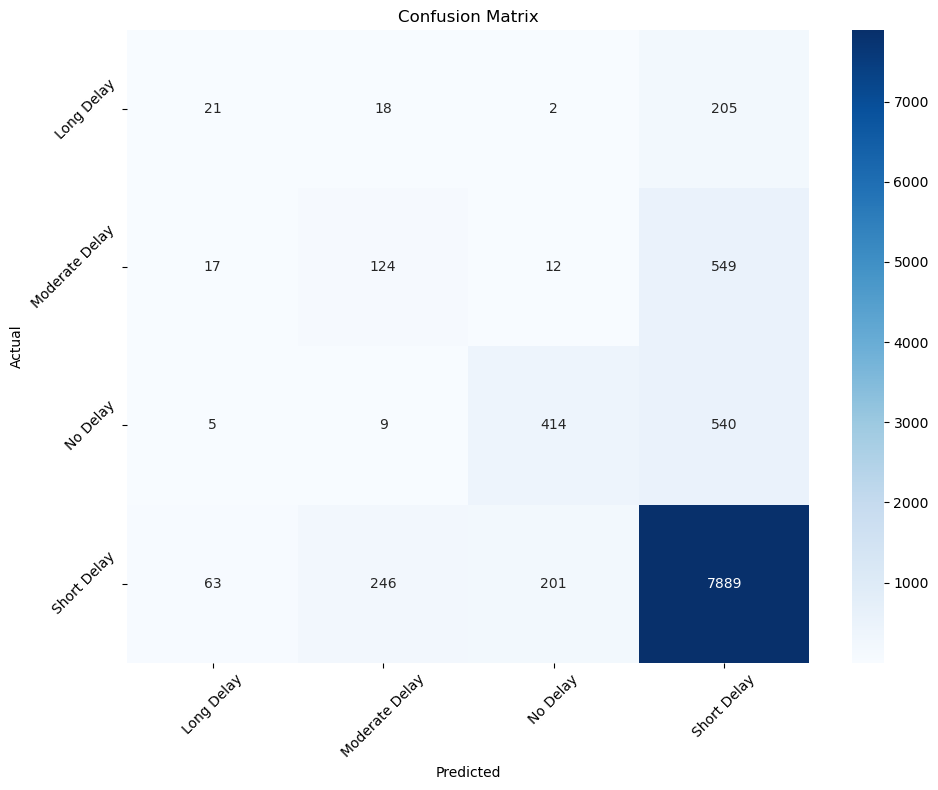


Test Set Prediction Distribution:
Short Delay       0.885044
No Delay          0.064118
Moderate Delay    0.038967
Long Delay        0.011871
Name: proportion, dtype: float64

Multi-class predictions saved to 'multiclass.csv'

Verification of submission file:
Columns: ['ID', 'Delay_Category']

Unique categories in submission:
['Short Delay' 'Moderate Delay' 'No Delay' 'Long Delay']

Sample of final submission file:
   ID Delay_Category
0   1    Short Delay
1   2    Short Delay
2   3    Short Delay
3   4    Short Delay
4   5    Short Delay
5   6    Short Delay
6   7    Short Delay
7   8    Short Delay
8   9    Short Delay
9  10    Short Delay


In [35]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


train_df = pd.read_csv('Full_trained.csv', low_memory=False)
test_df = pd.read_csv('Full_test.csv', low_memory=False)


def categorize_delay(delay):
    if delay <= 0:
        return 'No Delay'
    elif delay < 45:
        return 'Short Delay'
    elif delay <= 175:
        return 'Moderate Delay'
    else:
        return 'Long Delay'


train_df['Delay_Category'] = train_df['Departure Delay'].apply(categorize_delay)


le = LabelEncoder()
train_df['Delay_Category_Encoded'] = le.fit_transform(train_df['Delay_Category'])


print("Delay Category Distribution in Training Data:")
print(train_df['Delay_Category'].value_counts(normalize=True))
print("\nTotal samples:", len(train_df))


feature_columns = [
    'Hour of Day', 'Month of Year', 'Day of Month',
    'Max_Temperature', 'Avg_Temperature', 'Min_Temperature',
    'Max_Humidity', 'Avg_Humidity', 'Min_Humidity',
    'Max_Wind_Speed', 'Avg_Wind_Speed', 'Min_Wind_Speed',
    'Max_Pressure', 'Avg_Pressure', 'Min_Pressure',
    'Total_Precipitation'
]

categorical_columns = [
    'Flight Type', 'Departure IATA Code', 'Arrival IATA Code',
    'Airline ICAO Code', 'Day of Week'
]


for col in categorical_columns:
    cat_le = LabelEncoder()
    all_values = pd.concat([train_df[col], test_df[col]]).unique()
    cat_le.fit(all_values)
    train_df[f'{col}_Encoded'] = cat_le.transform(train_df[col])
    test_df[f'{col}_Encoded'] = cat_le.transform(test_df[col])
    feature_columns.append(f'{col}_Encoded')


from sklearn.model_selection import train_test_split
X = train_df[feature_columns].fillna(0)
y = train_df['Delay_Category_Encoded']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

#
print("\nTraining multi-class Random Forest model...")
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)


y_pred = rf_model.predict(X_val_scaled)


print("\nClassification Report:")
print(classification_report(y_val, y_pred, 
                          target_names=le.classes_))


plt.figure(figsize=(10, 8))
conf_matrix = confusion_matrix(y_val, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_,
            yticklabels=le.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.tight_layout()
plt.show()


X_test = test_df[feature_columns].fillna(0)
X_test_scaled = scaler.transform(X_test)
test_predictions_encoded = rf_model.predict(X_test_scaled)
test_predictions = le.inverse_transform(test_predictions_encoded)


submission_df = pd.DataFrame({
    'ID': range(1, len(test_predictions) + 1),
    'Delay_Category': test_predictions
})

print("\nTest Set Prediction Distribution:")
print(pd.Series(test_predictions).value_counts(normalize=True))


submission_df.to_csv('multiclass.csv', index=False)

print("\nMulti-class predictions saved to 'multiclass.csv'")


verification_df = pd.read_csv('multiclass.csv')
print("\nVerification of submission file:")
print("Columns:", verification_df.columns.tolist())
print("\nUnique categories in submission:")
print(verification_df['Delay_Category'].unique())
print("\nSample of final submission file:")
print(verification_df.head(10))

Delay Duration Statistics:
count    51572.000000
mean        25.357756
std         68.226059
min      -1266.266667
25%          9.000000
50%         13.000000
75%         25.350000
max       1450.733333
Name: Departure Delay, dtype: float64

Performing 5-fold cross-validation...

Fold 1 Results:
MAE: 23.72 minutes
RMSE: 61.51 minutes

Fold 2 Results:
MAE: 24.93 minutes
RMSE: 65.17 minutes

Fold 3 Results:
MAE: 25.17 minutes
RMSE: 62.53 minutes

Fold 4 Results:
MAE: 25.15 minutes
RMSE: 64.58 minutes

Fold 5 Results:
MAE: 26.04 minutes
RMSE: 70.22 minutes

Cross-validation Results:
Average MAE: 25.00 ± 0.74 minutes
Average RMSE: 64.80 ± 3.02 minutes

Training final model on full dataset...


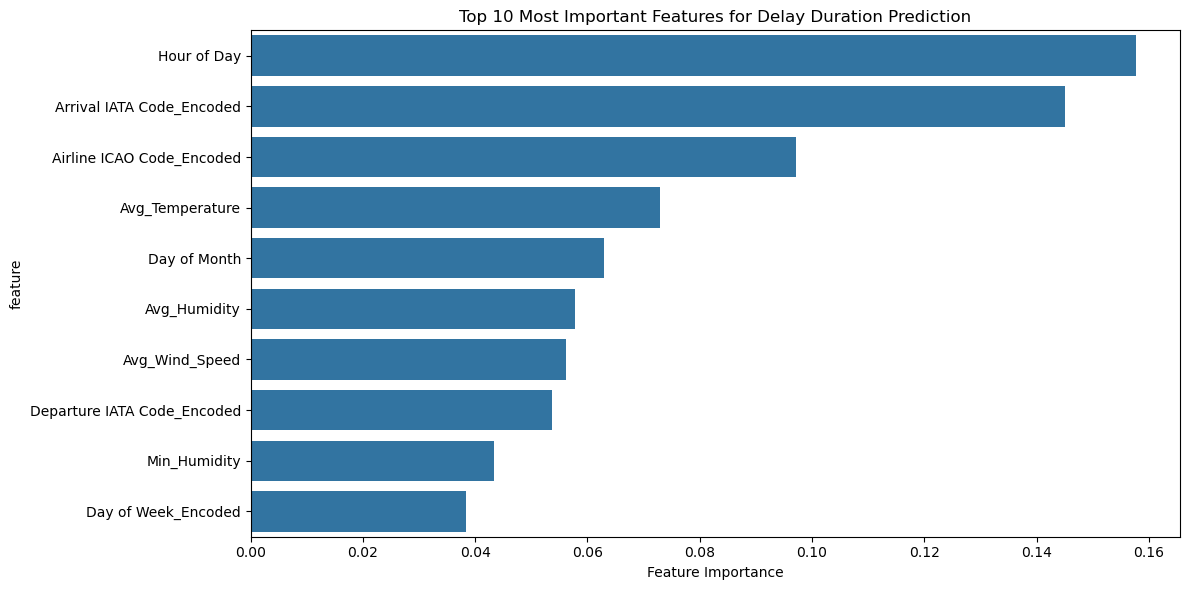


Test Set Prediction Statistics:
count    14910.000000
mean        27.066980
std         35.111612
min       -401.566791
25%         11.977666
50%         20.082522
75%         32.972743
max        423.932202
dtype: float64


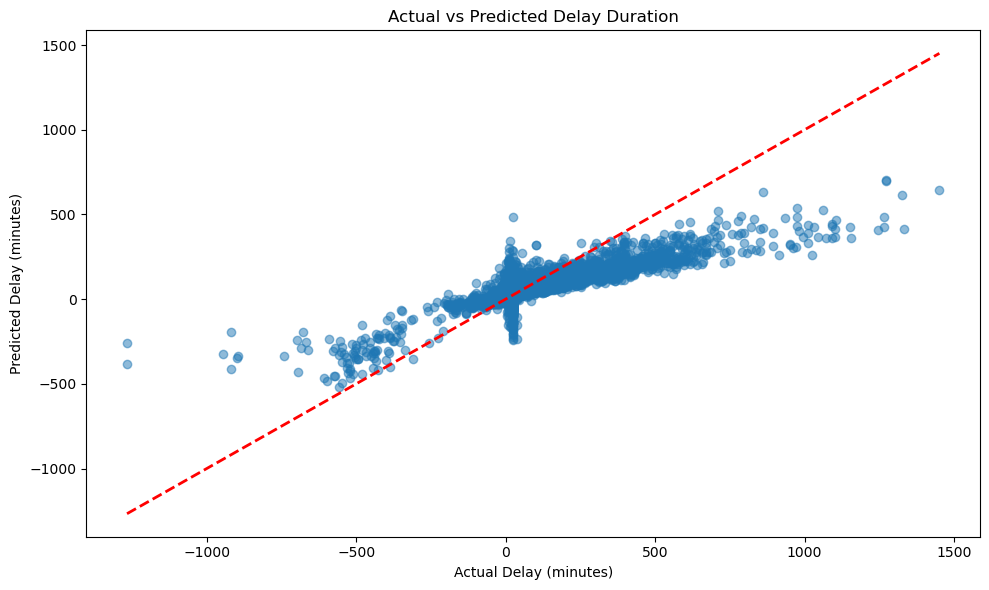

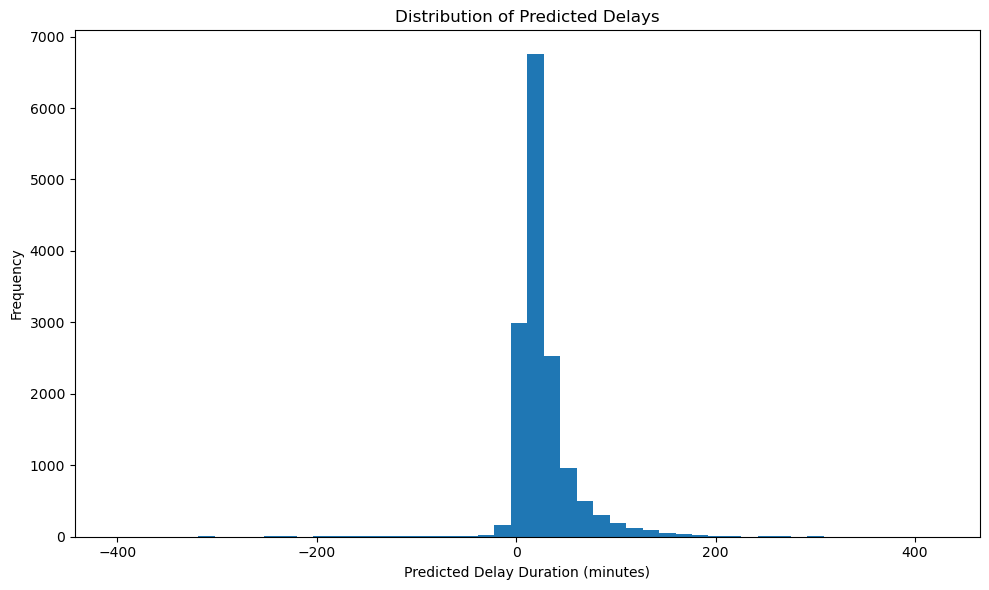

In [37]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error
import seaborn as sns
import matplotlib.pyplot as plt


train_df = pd.read_csv('Full_trained.csv', low_memory=False)
test_df = pd.read_csv('Full_test.csv', low_memory=False)


print("Delay Duration Statistics:")
print(train_df['Departure Delay'].describe())


feature_columns = [
    'Hour of Day', 'Month of Year', 'Day of Month',
    'Max_Temperature', 'Avg_Temperature', 'Min_Temperature',
    'Max_Humidity', 'Avg_Humidity', 'Min_Humidity',
    'Max_Wind_Speed', 'Avg_Wind_Speed', 'Min_Wind_Speed',
    'Max_Pressure', 'Avg_Pressure', 'Min_Pressure',
    'Total_Precipitation'
]

categorical_columns = [
    'Flight Type', 'Departure IATA Code', 'Arrival IATA Code',
    'Airline ICAO Code', 'Day of Week'
]


for col in categorical_columns:
    
    all_values = pd.concat([train_df[col], test_df[col]]).unique()
    mapping = {val: idx for idx, val in enumerate(all_values)}
    
    train_df[f'{col}_Encoded'] = train_df[col].map(mapping)
    test_df[f'{col}_Encoded'] = test_df[col].map(mapping)
    feature_columns.append(f'{col}_Encoded')


X = train_df[feature_columns].fillna(0)
y = train_df['Departure Delay'].fillna(0)


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


rf_regressor = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)


print("\nPerforming 5-fold cross-validation...")
kf = KFold(n_splits=5, shuffle=True, random_state=42)

mae_scores = []
rmse_scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X_scaled), 1):
  
    X_train_fold = X_scaled[train_idx]
    y_train_fold = y.iloc[train_idx]
    X_val_fold = X_scaled[val_idx]
    y_val_fold = y.iloc[val_idx]
    
   
    rf_regressor.fit(X_train_fold, y_train_fold)
    
    
    y_pred_fold = rf_regressor.predict(X_val_fold)
    
 
    mae = mean_absolute_error(y_val_fold, y_pred_fold)
    rmse = np.sqrt(mean_squared_error(y_val_fold, y_pred_fold))
    
    mae_scores.append(mae)
    rmse_scores.append(rmse)
    
    print(f"\nFold {fold} Results:")
    print(f"MAE: {mae:.2f} minutes")
    print(f"RMSE: {rmse:.2f} minutes")


print("\nCross-validation Results:")
print(f"Average MAE: {np.mean(mae_scores):.2f} ± {np.std(mae_scores):.2f} minutes")
print(f"Average RMSE: {np.mean(rmse_scores):.2f} ± {np.std(rmse_scores):.2f} minutes")

print("\nTraining final model on full dataset...")
rf_regressor.fit(X_scaled, y)


feature_importance = pd.DataFrame({
    'feature': feature_columns,
    'importance': rf_regressor.feature_importances_
})
feature_importance = feature_importance.sort_values('importance', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x='importance', y='feature', data=feature_importance.head(10))
plt.title('Top 10 Most Important Features for Delay Duration Prediction')
plt.xlabel('Feature Importance')
plt.tight_layout()
plt.show()


X_test = test_df[feature_columns].fillna(0)
X_test_scaled = scaler.transform(X_test)
test_predictions = rf_regressor.predict(X_test_scaled)


submission_df = pd.DataFrame({
    'ID': range(1, len(test_predictions) + 1),
    'Delay_Duration': test_predictions
})


submission_df.to_csv('regression.csv', index=False)


print("\nTest Set Prediction Statistics:")
print(pd.Series(test_predictions).describe())


plt.figure(figsize=(10, 6))
y_train_pred = rf_regressor.predict(X_scaled)
plt.scatter(y, y_train_pred, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
plt.xlabel('Actual Delay (minutes)')
plt.ylabel('Predicted Delay (minutes)')
plt.title('Actual vs Predicted Delay Duration')
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 6))
plt.hist(test_predictions, bins=50)
plt.xlabel('Predicted Delay Duration (minutes)')
plt.ylabel('Frequency')
plt.title('Distribution of Predicted Delays')
plt.tight_layout()
plt.show()

Loading datasets...

Training Data Class Distribution:
Delay_Binary
delayed    0.906189
on-time    0.093811
Name: proportion, dtype: float64

Total training samples: 51572

Total test samples: 14910

Training Random Forest model...

Validation Metrics:

Classification Report:
              precision    recall  f1-score   support

     on-time       0.70      0.46      0.55       968
     delayed       0.95      0.98      0.96      9347

    accuracy                           0.93     10315
   macro avg       0.82      0.72      0.76     10315
weighted avg       0.92      0.93      0.92     10315



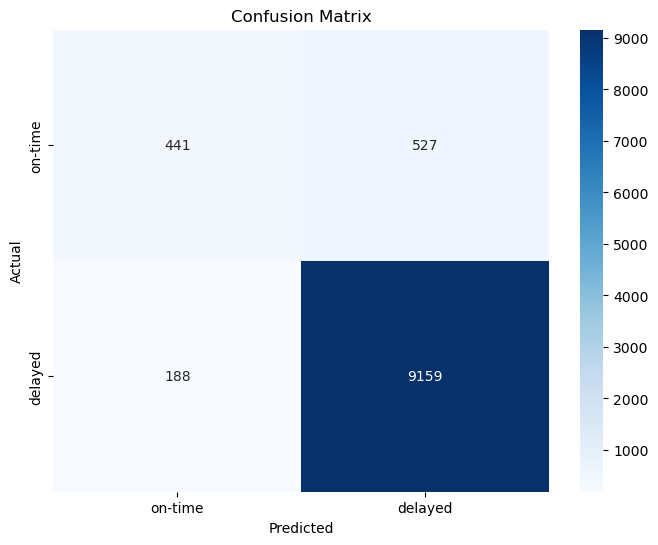


Submission File Preview:
   ID    Delay
0   1  delayed
1   2  delayed
2   3  delayed
3   4  delayed
4   5  delayed
5   6  delayed
6   7  delayed
7   8  delayed
8   9  delayed
9  10  delayed

Prediction Distribution in Test Set:
Delay
delayed    0.938431
on-time    0.061569
Name: proportion, dtype: float64

Total predictions: 14910

Submission File Information:
Columns: ['ID', 'Delay']
ID range: 1 to 14910
Unique values in Delay column: ['delayed' 'on-time']


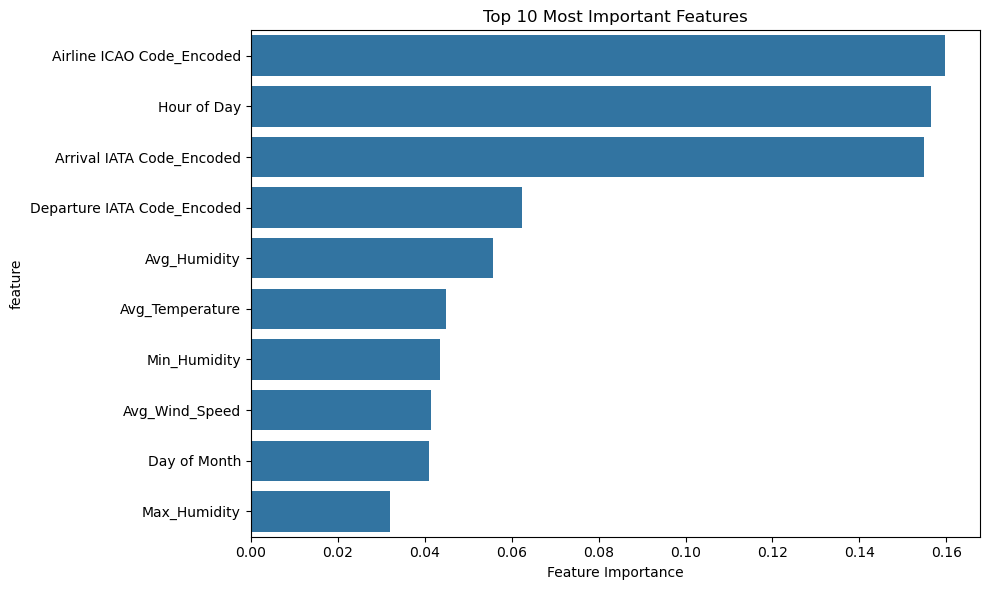


Final Verification Results:
1. File can be read successfully: True
2. Columns are correct: True
3. ID starts at 1: True
4. ID is sequential: True
5. Delay values are correct: True

Binary classification submission file 'binaryclass.csv' has been created with text labels 'on-time' and 'delayed'!

Sample of Final Submission File:
   ID    Delay
0   1  delayed
1   2  delayed
2   3  delayed
3   4  delayed
4   5  delayed
5   6  delayed
6   7  delayed
7   8  delayed
8   9  delayed
9  10  delayed


In [41]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt


print("Loading datasets...")
train_df = pd.read_csv('Full_trained.csv', low_memory=False)
test_df = pd.read_csv('Full_test.csv', low_memory=False)

# 2. Create Binary Labels
# 0 = on-time (delay <= 0)
# 1 = delayed (delay > 0)
train_df['Delay_Binary'] = (train_df['Departure Delay'] > 0).astype(int)


print("\nTraining Data Class Distribution:")
print(train_df['Delay_Binary'].map({0: 'on-time', 1: 'delayed'}).value_counts(normalize=True))
print("\nTotal training samples:", len(train_df))


feature_columns = [
    'Hour of Day', 'Month of Year', 'Day of Month',
    'Max_Temperature', 'Avg_Temperature', 'Min_Temperature',
    'Max_Humidity', 'Avg_Humidity', 'Min_Humidity',
    'Max_Wind_Speed', 'Avg_Wind_Speed', 'Min_Wind_Speed',
    'Max_Pressure', 'Avg_Pressure', 'Min_Pressure',
    'Total_Precipitation'
]

categorical_columns = [
    'Flight Type', 'Departure IATA Code', 'Arrival IATA Code',
    'Airline ICAO Code', 'Day of Week'
]


for col in categorical_columns:
    all_values = pd.concat([train_df[col], test_df[col]]).unique()
    mapping = {val: idx for idx, val in enumerate(all_values)}
    
    train_df[f'{col}_Encoded'] = train_df[col].map(mapping)
    test_df[f'{col}_Encoded'] = test_df[col].map(mapping)
    feature_columns.append(f'{col}_Encoded')


X_train = train_df[feature_columns].fillna(0)
y_train = train_df['Delay_Binary']
X_test = test_df[feature_columns].fillna(0)

print(f"\nTotal test samples: {len(X_test)}")


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


print("\nTraining Random Forest model...")
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)


X_train_split, X_val, y_train_split, y_val = train_test_split(
    X_train_scaled, y_train, test_size=0.2, random_state=42, stratify=y_train
)

rf_model.fit(X_train_split, y_train_split)


y_val_pred = rf_model.predict(X_val)

print("\nValidation Metrics:")
print("\nClassification Report:")
print(classification_report(y_val, y_val_pred, target_names=['on-time', 'delayed']))


plt.figure(figsize=(8, 6))
conf_matrix = confusion_matrix(y_val, y_val_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['on-time', 'delayed'],
            yticklabels=['on-time', 'delayed'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


rf_model.fit(X_train_scaled, y_train)
y_pred = rf_model.predict(X_test_scaled)


delay_mapping = {0: 'on-time', 1: 'delayed'}
text_predictions = [delay_mapping[pred] for pred in y_pred]

submission_df = pd.DataFrame({
    'ID': range(1, len(y_pred) + 1),
    'Delay': text_predictions
})

print("\nSubmission File Preview:")
print(submission_df.head(10))

print("\nPrediction Distribution in Test Set:")
print(submission_df['Delay'].value_counts(normalize=True))
print("\nTotal predictions:", len(submission_df))

print("\nSubmission File Information:")
print("Columns:", submission_df.columns.tolist())
print("ID range:", submission_df['ID'].min(), "to", submission_df['ID'].max())
print("Unique values in Delay column:", submission_df['Delay'].unique())


submission_df.to_csv('binaryclass.csv', index=False)


feature_importance = pd.DataFrame({
    'feature': feature_columns,
    'importance': rf_model.feature_importances_
})
feature_importance = feature_importance.sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feature_importance.head(10))
plt.title('Top 10 Most Important Features')
plt.xlabel('Feature Importance')
plt.tight_layout()
plt.show()


verification_df = pd.read_csv('binaryclass.csv')
print("\nFinal Verification Results:")
print("1. File can be read successfully:", len(verification_df) == len(y_pred))
print("2. Columns are correct:", verification_df.columns.tolist() == ['ID', 'Delay'])
print("3. ID starts at 1:", verification_df['ID'].min() == 1)
print("4. ID is sequential:", all(verification_df['ID'] == range(1, len(y_pred) + 1)))
print("5. Delay values are correct:", set(verification_df['Delay'].unique()) <= {'on-time', 'delayed'})

print("\nBinary classification submission file 'binaryclass.csv' has been created with text labels 'on-time' and 'delayed'!")


print("\nSample of Final Submission File:")
print(verification_df.head(10))

In [55]:
!pip install xgboost


  Using cached xgboost-2.1.3-py3-none-win_amd64.whl.metadata (2.1 kB)
   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
   ----

ERROR: Exception:
Traceback (most recent call last):
  File "E:\ANACONDA\Lib\site-packages\pip\_vendor\urllib3\response.py", line 438, in _error_catcher
    yield
  File "E:\ANACONDA\Lib\site-packages\pip\_vendor\urllib3\response.py", line 561, in read
    data = self._fp_read(amt) if not fp_closed else b""
           ^^^^^^^^^^^^^^^^^^
  File "E:\ANACONDA\Lib\site-packages\pip\_vendor\urllib3\response.py", line 527, in _fp_read
    return self._fp.read(amt) if amt is not None else self._fp.read()
           ^^^^^^^^^^^^^^^^^^
  File "E:\ANACONDA\Lib\site-packages\pip\_vendor\cachecontrol\filewrapper.py", line 98, in read
    data: bytes = self.__fp.read(amt)
                  ^^^^^^^^^^^^^^^^^^^
  File "E:\ANACONDA\Lib\http\client.py", line 479, in read
    s = self.fp.read(amt)
        ^^^^^^^^^^^^^^^^^
  File "E:\ANACONDA\Lib\socket.py", line 720, in readinto
    return self._sock.recv_into(b)
           ^^^^^^^^^^^^^^^^^^^^^^^
  File "E:\ANACONDA\Lib\ssl.py", line 1251, in recv_int

Loading data...

Performing Binary Classification Optimization...

Optimizing RandomForest for binary classification...

Best parameters for RandomForest:
{'class_weight': 'balanced', 'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Mean CV score: 0.8005 (+/- 0.0890)

Optimizing GradientBoosting for binary classification...

Best parameters for GradientBoosting:
{'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 100}
Mean CV score: 0.8617 (+/- 0.0003)

Optimizing DecisionTree for binary classification...

Best parameters for DecisionTree:
{'class_weight': 'balanced', 'max_depth': None, 'min_samples_split': 2}
Mean CV score: 0.7626 (+/- 0.0948)

Performing Multi-class Classification Optimization...

Optimizing RandomForest for multiclass classification...

Best parameters for RandomForest:
{'class_weight': 'balanced', 'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Mean CV score: 0.6864 (+/- 0.0328)

Optimizing GradientBoosting for multiclass classifi

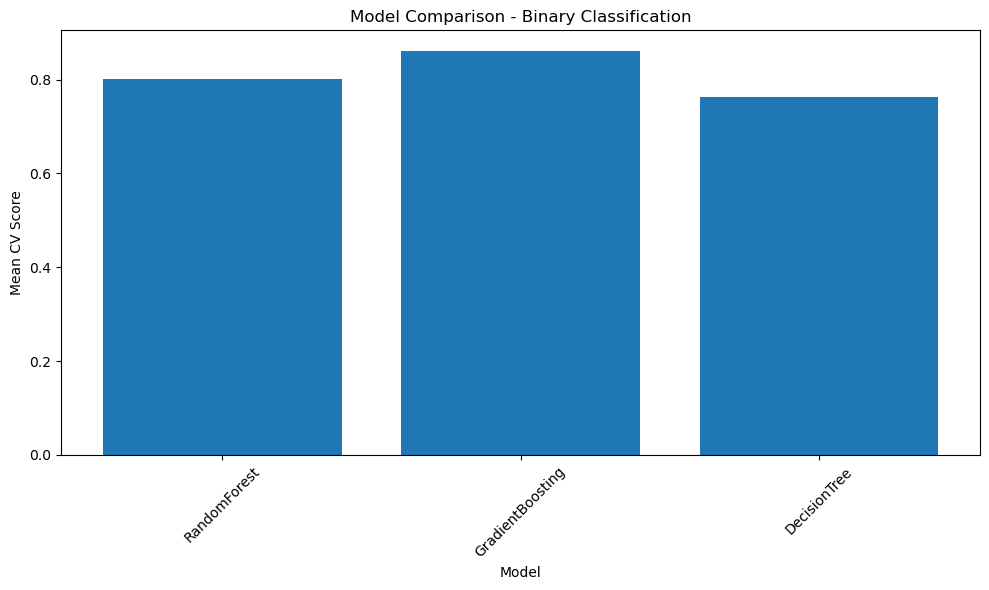

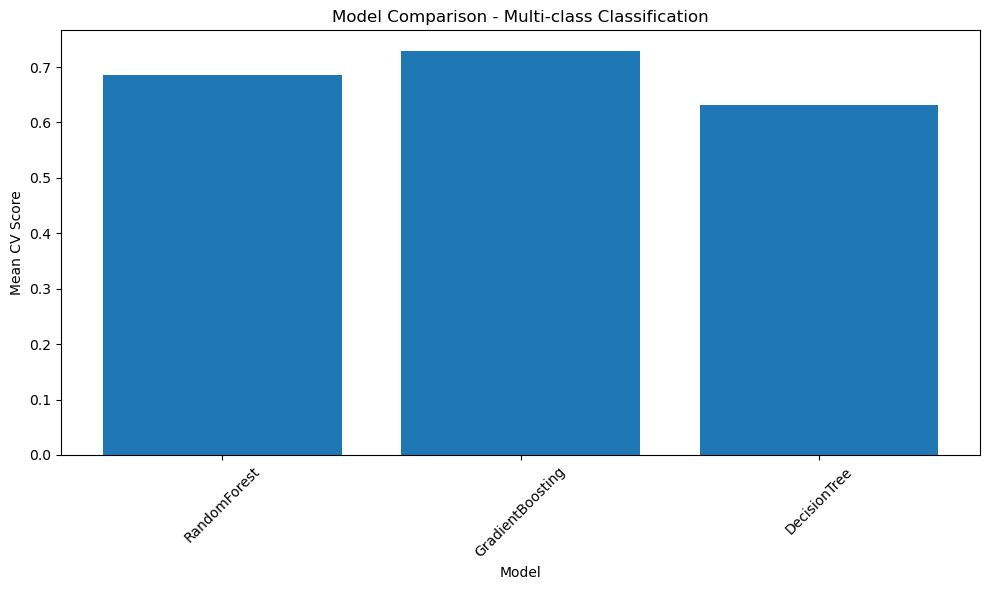

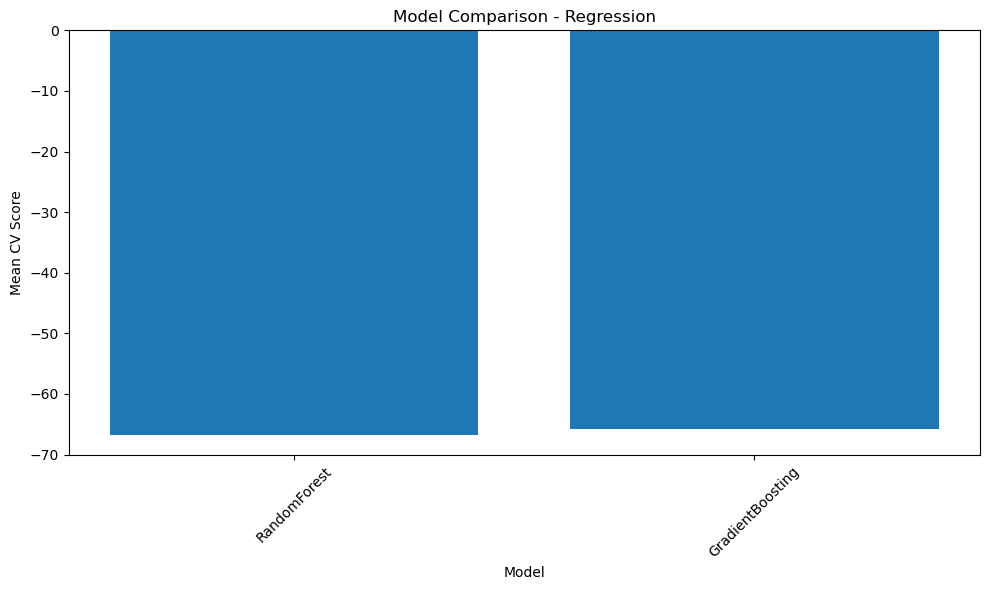


Optimization complete! Results have been saved to files.


In [59]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GridSearchCV, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.metrics import (classification_report, confusion_matrix, 
                           mean_absolute_error, mean_squared_error,
                           accuracy_score, f1_score)
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
import seaborn as sns
import matplotlib.pyplot as plt


print("Loading data...")
train_df = pd.read_csv('Full_trained.csv', low_memory=False)
test_df = pd.read_csv('Full_test.csv', low_memory=False)


def create_labels(df):
    
    df['Binary_Label'] = (df['Departure Delay'] > 0).astype(int)
    
   
    def get_delay_category(delay):
        if delay <= 0:
            return 'No Delay'
        elif delay < 45:
            return 'Short Delay'
        elif delay <= 175:
            return 'Moderate Delay'
        else:
            return 'Long Delay'
    
    df['Multiclass_Label'] = df['Departure Delay'].apply(get_delay_category)
    
    return df


feature_columns = [
    'Hour of Day', 'Month of Year', 'Day of Month',
    'Max_Temperature', 'Avg_Temperature', 'Min_Temperature',
    'Max_Humidity', 'Avg_Humidity', 'Min_Humidity',
    'Max_Wind_Speed', 'Avg_Wind_Speed', 'Min_Wind_Speed',
    'Max_Pressure', 'Avg_Pressure', 'Min_Pressure',
    'Total_Precipitation'
]

categorical_columns = [
    'Flight Type', 'Departure IATA Code', 'Arrival IATA Code',
    'Airline ICAO Code', 'Day of Week'
]


train_df = create_labels(train_df)

#
for col in categorical_columns:
    le = LabelEncoder()
    all_values = pd.concat([train_df[col], test_df[col]]).unique()
    le.fit(all_values)
    train_df[f'{col}_Encoded'] = le.transform(train_df[col])
    test_df[f'{col}_Encoded'] = le.transform(test_df[col])
    feature_columns.append(f'{col}_Encoded')


X = train_df[feature_columns].fillna(0)
y_binary = train_df['Binary_Label']
y_multi = train_df['Multiclass_Label']
y_reg = train_df['Departure Delay']


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


binary_models = {
    'RandomForest': {
        'model': RandomForestClassifier(),
        'params': {
            'n_estimators': [100, 200],
            'max_depth': [10, None],
            'min_samples_split': [2, 5],
            'class_weight': ['balanced']
        }
    },
    'GradientBoosting': {
        'model': GradientBoostingClassifier(),
        'params': {
            'n_estimators': [100, 200],
            'max_depth': [3, 6],
            'learning_rate': [0.01, 0.1]
        }
    },
    'DecisionTree': {
        'model': DecisionTreeClassifier(),
        'params': {
            'max_depth': [5, 10, None],
            'min_samples_split': [2, 5],
            'class_weight': ['balanced']
        }
    }
}


def optimize_and_evaluate(X, y, models, task='binary', cv=5):
    results = {}
    
    for name, model_info in models.items():
        print(f"\nOptimizing {name} for {task} classification...")
        
        
        grid_search = GridSearchCV(
            model_info['model'],
            model_info['params'],
            cv=cv,
            scoring='f1_weighted' if task != 'regression' else 'neg_root_mean_squared_error',
            n_jobs=-1
        )
        
        grid_search.fit(X, y)
        
        
        results[name] = {
            'best_params': grid_search.best_params_,
            'best_score': grid_search.best_score_,
            'cv_results': grid_search.cv_results_
        }
        
        
        best_model = grid_search.best_estimator_
        cv_scores = cross_val_score(
            best_model, X, y,
            cv=cv,
            scoring='f1_weighted' if task != 'regression' else 'neg_root_mean_squared_error'
        )
        
        results[name]['cv_scores'] = cv_scores
        
        print(f"\nBest parameters for {name}:")
        print(grid_search.best_params_)
        print(f"Mean CV score: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")
        
      
        final_model = best_model.fit(X, y)
        results[name]['final_model'] = final_model
    
    return results


print("\nPerforming Binary Classification Optimization...")
binary_results = optimize_and_evaluate(X_scaled, y_binary, binary_models, 'binary')

# Modify models for multi-class classification
multiclass_models = binary_models.copy()
print("\nPerforming Multi-class Classification Optimization...")
multiclass_results = optimize_and_evaluate(X_scaled, y_multi, multiclass_models, 'multiclass')

# Define regression models
regression_models = {
    'RandomForest': {
        'model': RandomForestRegressor(),
        'params': {
            'n_estimators': [100, 200],
            'max_depth': [10, None],
            'min_samples_split': [2, 5]
        }
    },
    'GradientBoosting': {
        'model': GradientBoostingRegressor(),
        'params': {
            'n_estimators': [100, 200],
            'max_depth': [3, 6],
            'learning_rate': [0.01, 0.1]
        }
    }
}

print("\nPerforming Regression Optimization...")
regression_results = optimize_and_evaluate(X_scaled, y_reg, regression_models, 'regression')

# Plot comparison of model performances
def plot_model_comparison(results, task):
    plt.figure(figsize=(10, 6))
    models = list(results.keys())
    scores = [results[model]['cv_scores'].mean() for model in models]
    
    plt.bar(models, scores)
    plt.title(f'Model Comparison - {task}')
    plt.xlabel('Model')
    plt.ylabel('Mean CV Score')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Plot comparisons
plot_model_comparison(binary_results, 'Binary Classification')
plot_model_comparison(multiclass_results, 'Multi-class Classification')
plot_model_comparison(regression_results, 'Regression')

# Save detailed results to file
def save_results(results, filename):
    with open(filename, 'w') as f:
        for model_name, model_results in results.items():
            f.write(f"\n{model_name} Results:\n")
            f.write(f"Best Parameters: {model_results['best_params']}\n")
            f.write(f"Mean CV Score: {model_results['cv_scores'].mean():.4f} "
                   f"(+/- {model_results['cv_scores'].std() * 2:.4f})\n")
            f.write("-" * 50 + "\n")

save_results(binary_results, 'binary_optimization_results.txt')
save_results(multiclass_results, 'multiclass_optimization_results.txt')
save_results(regression_results, 'regression_optimization_results.txt')

print("\nOptimization complete! Results have been saved to files.")

In [61]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

# Load data
print("Loading datasets...")
train_df = pd.read_csv('Full_trained.csv', low_memory=False)
test_df = pd.read_csv('Full_test.csv', low_memory=False)

# Feature preparation
feature_columns = [
    'Hour of Day', 'Month of Year', 'Day of Month',
    'Max_Temperature', 'Avg_Temperature', 'Min_Temperature',
    'Max_Humidity', 'Avg_Humidity', 'Min_Humidity',
    'Max_Wind_Speed', 'Avg_Wind_Speed', 'Min_Wind_Speed',
    'Max_Pressure', 'Avg_Pressure', 'Min_Pressure',
    'Total_Precipitation'
]

categorical_columns = [
    'Flight Type', 'Departure IATA Code', 'Arrival IATA Code',
    'Airline ICAO Code', 'Day of Week'
]

# 1. Binary Classification Preparation
train_df['Binary_Label'] = (train_df['Departure Delay'] > 0).astype(int)

# 2. Multi-class Classification Preparation
def get_delay_category(delay):
    if delay <= 0:
        return 'No Delay'
    elif delay < 45:
        return 'Short Delay'
    elif delay <= 175:
        return 'Moderate Delay'
    else:
        return 'Long Delay'

train_df['Multiclass_Label'] = train_df['Departure Delay'].apply(get_delay_category)

# Encode categorical variables
for col in categorical_columns:
    le = LabelEncoder()
    all_values = pd.concat([train_df[col], test_df[col]]).unique()
    le.fit(all_values)
    train_df[f'{col}_Encoded'] = le.transform(train_df[col])
    test_df[f'{col}_Encoded'] = le.transform(test_df[col])
    feature_columns.append(f'{col}_Encoded')

# Prepare features
X_train = train_df[feature_columns].fillna(0)
y_binary = train_df['Binary_Label']
y_multi = train_df['Multiclass_Label']
y_reg = train_df['Departure Delay']

X_test = test_df[feature_columns].fillna(0)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 1. Binary Classification
print("\nPerforming Binary Classification...")
binary_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

binary_model.fit(X_train_scaled, y_binary)
binary_pred = binary_model.predict(X_test_scaled)

# Create binary submission with text labels
binary_submission = pd.DataFrame({
    'ID': range(1, len(binary_pred) + 1),
    'Delay': ['delayed' if pred == 1 else 'on-time' for pred in binary_pred]
})

# 2. Multi-class Classification
print("\nPerforming Multi-class Classification...")
multiclass_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

le_multi = LabelEncoder()
y_multi_encoded = le_multi.fit_transform(y_multi)
multiclass_model.fit(X_train_scaled, y_multi_encoded)
multiclass_pred = le_multi.inverse_transform(multiclass_model.predict(X_test_scaled))

# Create multi-class submission
multiclass_submission = pd.DataFrame({
    'ID': range(1, len(multiclass_pred) + 1),
    'Delay_Category': multiclass_pred
})

# 3. Regression
print("\nPerforming Regression...")
regression_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

regression_model.fit(X_train_scaled, y_reg)
regression_pred = regression_model.predict(X_test_scaled)

# Create regression submission
regression_submission = pd.DataFrame({
    'ID': range(1, len(regression_pred) + 1),
    'Delay_Duration': regression_pred.round(2)  # Round to 2 decimal places
})

# Save submissions
binary_submission.to_csv('binaryclass.csv', index=False)
multiclass_submission.to_csv('multiclass.csv', index=False)
regression_submission.to_csv('regression.csv', index=False)

# Verify submissions
print("\nVerifying submission files...")

# Binary Classification Verification
print("\nBinary Classification Submission:")
print("Sample of binaryclass.csv:")
print(binary_submission.head())
print("\nUnique values:", binary_submission['Delay'].unique())

# Multi-class Classification Verification
print("\nMulti-class Classification Submission:")
print("Sample of multiclass.csv:")
print(multiclass_submission.head())
print("\nUnique values:", multiclass_submission['Delay_Category'].unique())

# Regression Verification
print("\nRegression Submission:")
print("Sample of regression.csv:")
print(regression_submission.head())
print("\nDelay Duration Statistics:")
print(regression_submission['Delay_Duration'].describe())

# Final verification
print("\nFinal Verification:")
for filename, expected_cols in [
    ('binaryclass.csv', ['ID', 'Delay']),
    ('multiclass.csv', ['ID', 'Delay_Category']),
    ('regression.csv', ['ID', 'Delay_Duration'])
]:
    df = pd.read_csv(filename)
    print(f"\n{filename}:")
    print(f"- Rows: {len(df)}")
    print(f"- Columns: {df.columns.tolist()}")
    print(f"- ID range: {df['ID'].min()} to {df['ID'].max()}")
    if filename == 'binaryclass.csv':
        print(f"- Unique values in Delay: {df['Delay'].unique()}")

Loading datasets...

Performing Binary Classification...

Performing Multi-class Classification...

Performing Regression...

Verifying submission files...

Binary Classification Submission:
Sample of binaryclass.csv:
   ID    Delay
0   1  delayed
1   2  delayed
2   3  delayed
3   4  delayed
4   5  delayed

Unique values: ['delayed' 'on-time']

Multi-class Classification Submission:
Sample of multiclass.csv:
   ID Delay_Category
0   1    Short Delay
1   2    Short Delay
2   3    Short Delay
3   4    Short Delay
4   5    Short Delay

Unique values: ['Short Delay' 'Moderate Delay' 'No Delay' 'Long Delay']

Regression Submission:
Sample of regression.csv:
   ID  Delay_Duration
0   1           12.49
1   2           33.49
2   3           51.75
3   4           19.65
4   5           35.72

Delay Duration Statistics:
count    14910.000000
mean        26.921246
std         34.211609
min       -438.740000
25%         12.322500
50%         19.950000
75%         32.620000
max        517.550000
Nam